# 03 Explaining A1 (LFCC-GMM)
A1 scores every 10 ms frame as log p(frame | bona fide GMM) − log p(frame | spoof GMM) and averages. So we can see which frames drive the decision.

In [1]:
import json
from pathlib import Path
import librosa
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from audio_df.data.manifests import load_manifest
from audio_df.helpers.audio import load_audio
from audio_df.helpers.eval_audio import TRIM_RECIPE, trimmed_manifest
from audio_df.helpers.metrics import compute_eer
from audio_df.helpers.research import stats, visualization as viz
from audio_df.modules.detector import GMMDetector

SR, HOP = 16000, 160
a1 = GMMDetector.load("../artifacts/a1/20261020-134519-735144")
run = Path("../runs/E-20261020-153158-819171-a1")

def eer(scores, labels):
    return round(100 * compute_eer(scores, labels, higher_is_spoof=False)[0], 2)

def frame_llr(path):
    """Per-frame A1 score, plus a speech mask using the same silence rule as trimming."""
    x = load_audio(path, SR)
    f = a1.features(x)
    llr = a1.bonafide.score_log_likelihood(f) - a1.spoof.score_log_likelihood(f)
    speech = np.zeros(len(x), bool)
    for s, e in librosa.effects.split(x, top_db=TRIM_RECIPE["top_db"], frame_length=TRIM_RECIPE["frame_length"],
                                      hop_length=TRIM_RECIPE["hop_length"]):
        speech[s:e] = True
    return x, llr, speech[np.minimum(np.arange(len(llr)) * HOP + HOP, len(x) - 1)]

def decompose(df):
    rows = []
    for r in df.itertuples():
        _, llr, sp = frame_llr(r.path)
        rows.append({"label": r.label, "all frames": llr.mean(), "speech only": llr[sp].mean(),
                     "silence only": llr[~sp].mean() if (~sp).any() else 0.0, "silence %": 100 * (1 - sp.mean())})
    return pd.DataFrame(rows)

d:\MyCode\projects\GC2-EchoJEV\SystemCode\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1 Results (trimmed ASVspoof 2019, raw ITW)

In [2]:
dev_eer = json.loads((run / "metrics_eval.json").read_text())["dev_eer"]
pd.Series({"dev": dev_eer} | {p.stem[8:]: json.loads(p.read_text())["eer"] for p in run.glob("metrics_*.json")},
          name="EER %").mul(100).round(2)

dev                 12.35
eval                21.05
eval_clean10k       21.80
eval_mp3_32k        42.54
eval_noise_10db     41.20
eval_opus_16k       25.56
eval_resample_8k    35.47
itw                 56.98
Name: EER %, dtype: float64

EER is very high, performance very bad for evaulation on other datasets. model is overfitting on certain features, which is silence leading (confirm below). 

## 2 Which frames decide?
200 bona fide + 200 spoof dev clips. Raw audio, frames split into speech vs silence.

In [3]:
dev = load_manifest("../data/manifests/dev.csv", "..")
sub = dev.groupby("label").sample(200, random_state=0)
trim = trimmed_manifest(dev, "../data/cache", "dev").set_index("utt_id").loc[sub.utt_id]
d = decompose(sub)
d["trimmed audio"] = [a1.score_file(p) for p in trim.path]
d.groupby("label").mean().round(2)

Trim audio dev: cache hit (24,844 clips)


,all frames,speech only,silence only,silence %,trimmed audio
label,,,,,
bonafide,1.33,0.97,1.78,46.22,0.97
spoof,-2.99,-1.59,-6.41,30.91,-1.64


In [4]:
pd.Series({c: eer(d[c], d.label) for c in ["all frames", "speech only", "silence only", "trimmed audio"]}, name="EER %")

all frames        3.5
speech only      12.0
silence only      6.5
trimmed audio    10.5
Name: EER %, dtype: float64

Silence frames are the strongest evidence: spoof silence scores -6.4 vs bona fide +1.8, and silence frames alone get 6.5% EER vs 12% for speech frames. Bona fide clips also have more silence (46% vs 31%), so the raw average gets an extra push. Remove the silence (trimmed audio) and A1 goes from 3.5% to 10.5% on this sample.

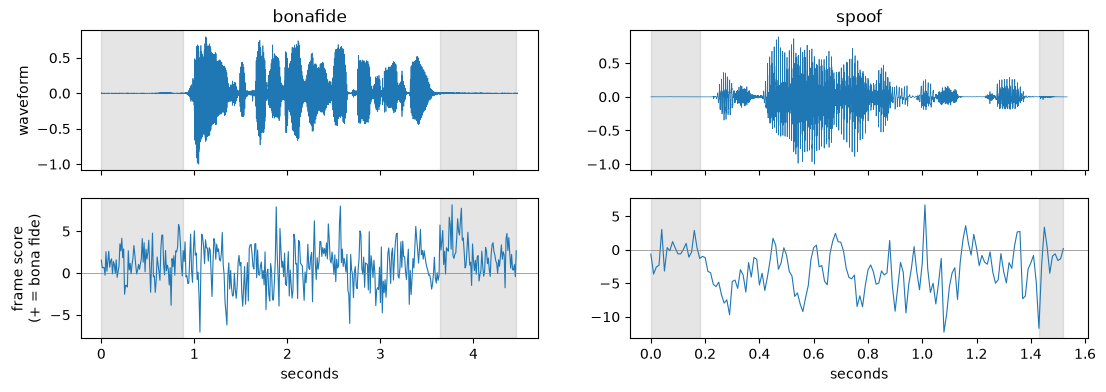

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(13, 4), sharex="col")
for col, lab in enumerate(["bonafide", "spoof"]):
    x, llr, sp = frame_llr(sub[sub.label == lab].path.iloc[0])
    t = np.arange(len(llr)) * HOP / SR
    axes[0, col].plot(np.arange(len(x)) / SR, x, lw=0.5)
    axes[0, col].set_title(lab)
    axes[1, col].plot(t, llr, lw=0.8)
    axes[1, col].axhline(0, color="grey", lw=0.5)
    axes[1, col].set_xlabel("seconds")
    for ax in axes[:, col]:
        ax.fill_between(t, 0, 1, where=~sp, transform=ax.get_xaxis_transform(), color="grey", alpha=0.2)
axes[0, 0].set_ylabel("waveform")
axes[1, 0].set_ylabel("frame score\n(+ = bona fide)")
plt.show()

Grey = silence. A1's clip score is the mean of the bottom line.

## 3 What's left after trimming
Mean log power spectrum of the trimmed clips, and spoof − bona fide effect size per frequency.

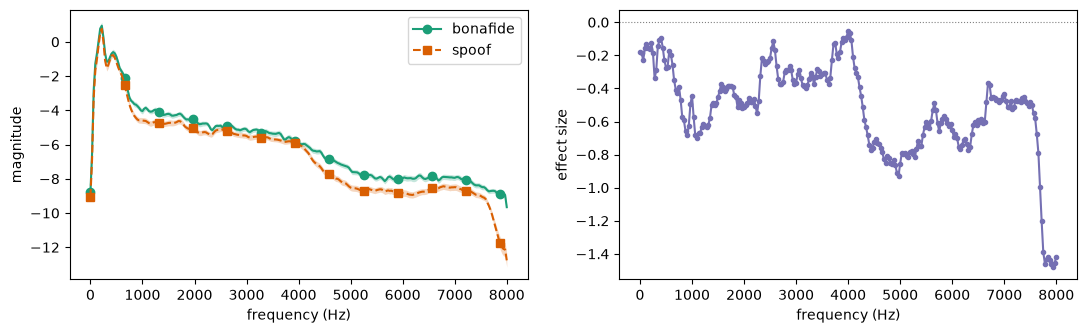

In [6]:
def spectrum(path):
    return np.log(np.abs(librosa.stft(load_audio(path, SR), n_fft=512)) ** 2 + 1e-10).mean(axis=1)

spec = {lab: np.stack([spectrum(p) for p in trim.path[sub.label.to_numpy() == lab]]) for lab in ["bonafide", "spoof"]}
freqs = librosa.fft_frequencies(sr=SR, n_fft=512)
fig, (a, b) = plt.subplots(1, 2, figsize=(13, 3.5))
viz.plot_mean_spectrum_with_ci(spec, freqs, ax=a)
viz.plot_effect_size_per_bin(stats.per_bin_effect_size(spec["spoof"], spec["bonafide"]), freqs, ax=b)
plt.show()

Spoof speech has less energy at every frequency, most at 4–5 kHz and above 7.5 kHz (d ≈ -1.4 near 8 kHz). That high band is what A1 still uses after trimming.

## 4 Per attack (full trimmed eval)

In [7]:
ev = pd.read_csv(run / "scores/eval.csv")
bona = ev[ev.label == "bonafide"]
pd.Series({a: eer(pd.concat([bona, g]).score, pd.concat([bona, g]).label)
           for a, g in ev[ev.label == "spoof"].groupby("attack_id")}, name="EER %").sort_values()

A09     0.35
A08     1.32
A11     1.34
A17     2.68
A14     4.36
A15     5.98
A19    12.01
A18    22.59
A13    27.11
A07    28.96
A16    33.17
A10    37.08
A12    37.39
Name: EER %, dtype: float64

A1 is good on some attacks (A08, A09, A11 < 1.5%) and near chance on others (A10, A12, A16 > 33%). A16 is the same system as training attack A04, so even a seen attack is missed once silence is gone.

## 5 In-the-Wild
Same split into speech vs silence frames, 200 clips per class.

In [8]:
itw = load_manifest("../data/manifests/itw.csv", "..").groupby("label").sample(200, random_state=0)
di = decompose(itw)
print(pd.Series({c: eer(di[c], di.label) for c in ["all frames", "speech only", "silence only"]}, name="EER %"))
di.groupby("label").mean().round(2)

all frames      57.5
speech only     64.0
silence only    56.5
Name: EER %, dtype: float64


,all frames,speech only,silence only,silence %
label,,,,
bonafide,0.47,0.47,0.28,15.03
spoof,0.45,0.86,-1.55,15.26


No silence cue in ITW (both classes ~15% silence), and on speech frames ITW spoofs look more bona fide than real ones (0.86 vs 0.47), so A1 is worse than chance. What A1 learned from 2019 speech doesn't transfer.